# Assignment 07: Critique, Redesign, and Explain Cardiac Rehab Charts

`README.md` gives each task's steps and checkpoints; the headings here match its numbering. Run each cell with `Shift+Enter`. When you finish, click **Restart**, then **Run All**, and run `python3 check_assignment.py` in the terminal.

In [8]:
import json
from pathlib import Path

import altair as alt
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("matplotlib:", matplotlib.__version__)
print("Altair:", alt.__version__)

DATA_DIR = Path("data")
PATIENTS_PATH = DATA_DIR / "rehab_patients.csv"
ATTENDANCE_PATH = DATA_DIR / "session_attendance.csv"
FOLLOWUP_PATH = DATA_DIR / "followup_goals.csv"

OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)
EXPLORATORY_SPEC_PATH = OUTPUT_DIR / "exploratory_spec.json"
EVIDENCE_PATH = OUTPUT_DIR / "visualization_evidence.json"
REDESIGN_PATH = OUTPUT_DIR / "critique_redesign.png"
SUPPORTING_DATA_PATH = OUTPUT_DIR / "explanatory_supporting_data.csv"
EXPLANATORY_PATH = OUTPUT_DIR / "explanatory_chart.png"
TEXT_ALTERNATIVE_PATH = OUTPUT_DIR / "explanatory_text_alternative.txt"

BLUE = "#0072B2"  # colorblind-safe blue
ORANGE = "#E69F00"  # colorblind-safe orange

print("data files found:", PATIENTS_PATH.exists() and ATTENDANCE_PATH.exists() and FOLLOWUP_PATH.exists())

NumPy: 2.3.3
pandas: 3.0.5
matplotlib: 3.11.1
Altair: 5.5.0
data files found: True


## Task 1: Explore the rehab patients with Altair

### 1.1 Load the patients and build the scatter plot

> **Checkpoint: `output/exploratory_spec.json`**
> A Vega-Lite specification with a `point` mark, `x`, `y`, `color`, and `shape` encodings, and the twelve patients embedded.

In [10]:
patients = pd.read_csv(PATIENTS_PATH)  # TODO: read PATIENTS_PATH with pd.read_csv

print("Shape of patients:", patients.shape)
print("Data types of patients:")
print(patients.dtypes)

exploratory_chart = (
    alt.Chart(patients)
    .mark_point(filled=True, size=90)
    .encode(
        x=alt.X(
            "sessions_attended:Q",
            title="Sessions attended (of 36)"
        ),
        y=alt.Y(
            "walk_distance_m:Q",
            title="Six-minute walk distance (m)",
            scale=alt.Scale(zero=False)
        ),
        color=alt.Color(
            "program:N",
            title="Program"
        ),
        shape=alt.Shape(
            "program:N",
            title="Program"
        ),
        tooltip=[
            "patient_id:N",
            "program:N",
            "sessions_attended:Q",
            "walk_distance_m:Q"
        ]
    )
    .properties(
        title="Sessions attended and walking distance at discharge"
    )
)

exploratory_chart.save(EXPLORATORY_SPEC_PATH)

exploratory_chart

Shape of patients: (12, 4)
Data types of patients:
patient_id             str
program                str
sessions_attended    int64
walk_distance_m      int64
dtype: object


alt.Chart(...)

### 1.2 Describe what the chart shows

In the chart, we explore whether who atteended more cardiac rehabilitation sessions tended to walk farther during the six-minute walk test at discharge and whether this pattern differs between the hHome-based and Center-based programs. One point represents one patient. One pattern I see is that patients who attended more sessions appear to have greater walking distances at discharge. Twelve patients cannot show that attending more sessions causes a longer walk because the sample size is too small.


## Task 2: Critique and redesign a misleading chart

### 2.1 Inspect the draft chart

The next cell draws a draft chart from the rehab service's dashboard. Run it and look at the chart before you start Task 2.2.

,program,quarter,attended_pct
0,Home-based,Q1,81
1,Home-based,Q2,77
2,Center-based,Q1,82
3,Center-based,Q2,80


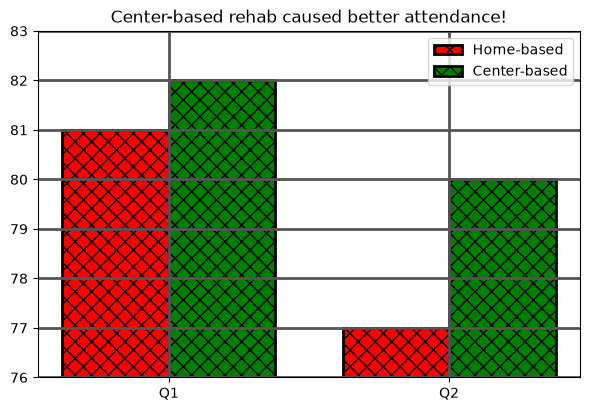

In [11]:
attendance = pd.read_csv(ATTENDANCE_PATH)
display(attendance)

quarters = ["Q1", "Q2"]
x = np.arange(len(quarters))  # [0 1]: one position per quarter
width = 0.38
home = attendance.loc[attendance["program"] == "Home-based", "attended_pct"]
center = attendance.loc[attendance["program"] == "Center-based", "attended_pct"]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(x - width / 2, home, width, label="Home-based", color="red",
       hatch="xx", edgecolor="black", linewidth=2)
ax.bar(x + width / 2, center, width, label="Center-based", color="green",
       hatch="xx", edgecolor="black", linewidth=2)
ax.set_xticks(x, quarters)
ax.set_ylim(76, 83)
ax.grid(True, linewidth=2, color="#555555")
ax.set_title("Center-based rehab caused better attendance!")
ax.legend()
plt.show()

### 2.2 Write the critique

Fill in a `problem` and a `repair` for each category, then run the cell to save the critique.

> **Checkpoint: `output/visualization_evidence.json`**
> An object with the key `critique`: a list of five entries, each with the keys `category`, `problem`, and `repair`.

In [33]:
critique = [
    {"category": "unsupported claim", "problem": "This claim is not supported by the data.", "repair": "Add supporting evidence or remove the claim."},  # TODO: fill in each problem and repair
    {"category": "truncated baseline", "problem": "The baseline is incomplete.", "repair": "Include all relevant baseline data."},
    {"category": "missing unit", "problem": "The units are missing.", "repair": "Add appropriate units to all measurements."},
    {"category": "color-only encoding", "problem": "The visualization uses only color to encode information.", "repair": "Use additional visual elements like shape or size to encode information."},
    {"category": "distracting decoration", "problem": "The visualization has unnecessary decorative elements.", "repair": "Remove or minimize decorative elements that do not add value."},
]

for entry in critique:
    print(f"{entry['category']}: {entry['problem']}")
    print(f"    repair: {entry['repair']}")

with open(EVIDENCE_PATH, "w", encoding="utf-8") as file:
    json.dump({"critique": critique}, file, indent=2, ensure_ascii=False)

unsupported claim: This claim is not supported by the data.
    repair: Add supporting evidence or remove the claim.
truncated baseline: The baseline is incomplete.
    repair: Include all relevant baseline data.
missing unit: The units are missing.
    repair: Add appropriate units to all measurements.
color-only encoding: The visualization uses only color to encode information.
    repair: Use additional visual elements like shape or size to encode information.
distracting decoration: The visualization has unnecessary decorative elements.
    repair: Remove or minimize decorative elements that do not add value.


### 2.3 Redesign the chart

> **Checkpoint: `output/critique_redesign.png`**
> Your redesigned chart as a PNG image.

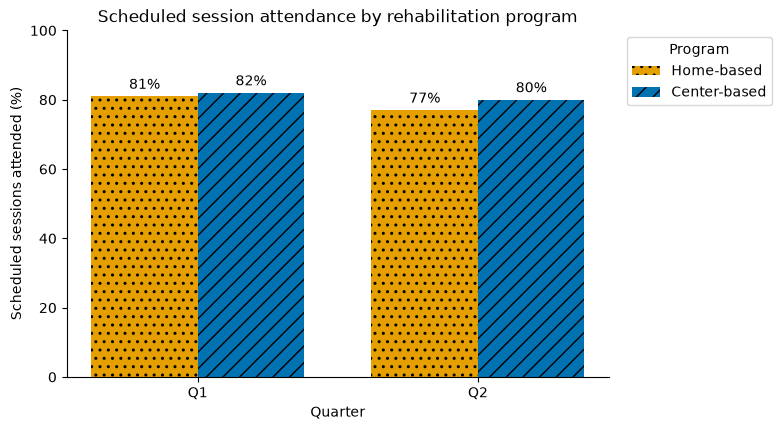

y-axis runs from 0.0 to 100.0


In [24]:
redesign_fig, redesign_ax = plt.subplots(figsize=(7, 4.5))

home_bars = redesign_ax.bar(
    x - width / 2,
    home,
    width,
    label="Home-based",
    color=ORANGE,
    hatch=".."
)

center_bars = redesign_ax.bar(
    x + width / 2,
    center,
    width,
    label="Center-based",
    color=BLUE,
    hatch="//"
)

redesign_ax.set_xticks(x, quarters)
redesign_ax.set_xlabel("Quarter")
redesign_ax.set_ylabel("Scheduled sessions attended (%)")
redesign_ax.set_ylim(0, 100)

redesign_ax.set_title(
    "Scheduled session attendance by rehabilitation program"
)

redesign_ax.bar_label(home_bars, fmt="%d%%", padding=3)
redesign_ax.bar_label(center_bars, fmt="%d%%", padding=3)

redesign_ax.spines["top"].set_visible(False)
redesign_ax.spines["right"].set_visible(False)

redesign_ax.legend(
    title="Program",
    loc="upper left",
    bbox_to_anchor=(1.02, 1)
)

redesign_fig.savefig(REDESIGN_PATH, dpi=150, bbox_inches="tight")

plt.show()
bottom, top = redesign_ax.get_ylim()
print("y-axis runs from", bottom, "to", top)

## Task 3: Explain one finding to the program coordinator

### 3.1 Write the contract and save the supporting data

> **Checkpoint: `output/explanatory_supporting_data.csv`**
> The header line `program,visit_number,goal_met_pct`, then the eight rows of `data/followup_goals.csv`.

In [14]:
followup = pd.read_csv(FOLLOWUP_PATH)
display(followup)

question = (
    "How does the percentage of patients meeting the weekly exercise goal "
    "change across follow-up visits for the Home-based and Center-based programs?"
)

audience = (
    "The cardiac rehabilitation program coordinator, who will use the chart "
    "to identify where additional follow-up support may be needed."
)

intended_claim = (
    "The percentage meeting the exercise goal increased across visits in both "
    "programs, with Center-based patients having a higher percentage than "
    "Home-based patients at visit 4."
)

y_measure = (
    "Percentage of patients seen at each follow-up visit who met the weekly "
    "exercise goal of 150 minutes (%)"
)

grain = (
    "One row and one plotted point represent one rehabilitation program at "
    "one follow-up visit."
)

data_types = {
    "program": "categorical",
    "visit_number": "ordinal",
    "goal_met_pct": "quantitative",
}

supporting_data = followup[
    ["program", "visit_number", "goal_met_pct"]
].copy()

supporting_data.to_csv(
    SUPPORTING_DATA_PATH,
    index=False
)

round_trip = pd.read_csv(SUPPORTING_DATA_PATH)
print("shape:", round_trip.shape)
print("same as saved:", round_trip.equals(supporting_data))

,program,visit_number,patients_seen,goal_met_pct
0,Home-based,1,48,58
1,Home-based,2,46,63
2,Home-based,3,45,67
3,Home-based,4,44,70
4,Center-based,1,52,57
5,Center-based,2,50,65
6,Center-based,3,49,72
7,Center-based,4,47,79


shape: (8, 3)
same as saved: True


### 3.2 Draw the explanatory chart

> **Checkpoint: `output/explanatory_chart.png`**
> Your explanatory line chart as a PNG image.

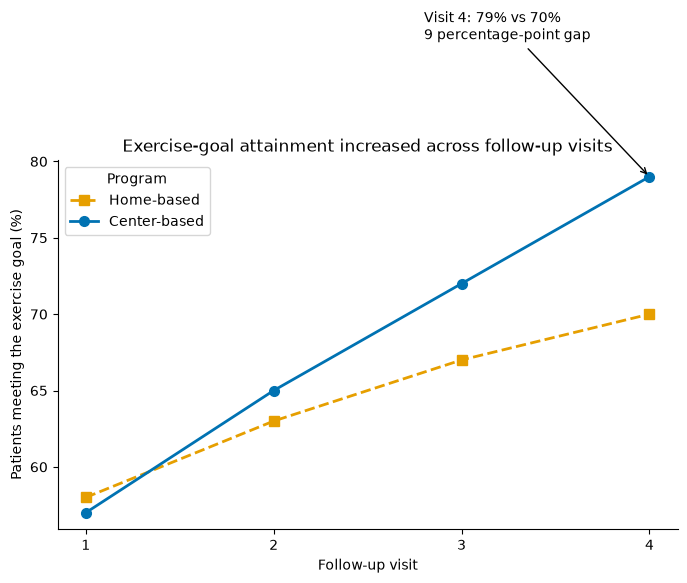

In [34]:
home_goals = supporting_data.loc[supporting_data["program"] == "Home-based"]
center_goals = supporting_data.loc[supporting_data["program"] == "Center-based"]

explanatory_fig, explanatory_ax = plt.subplots(figsize=(8, 4.8))

explanatory_ax.plot(
    home_goals["visit_number"],
    home_goals["goal_met_pct"],
    color=ORANGE,
    marker="s",
    linestyle="--",
    linewidth=2,
    markersize=7,
    label="Home-based"
)

explanatory_ax.plot(
    center_goals["visit_number"],
    center_goals["goal_met_pct"],
    color=BLUE,
    marker="o",
    linestyle="-",
    linewidth=2,
    markersize=7,
    label="Center-based"
)

explanatory_ax.annotate(
    "Visit 4: 79% vs 70%\n9 percentage-point gap",
    xy=(4, 79),
    xytext=(2.8, 88),
    arrowprops={"arrowstyle": "->"},
)

explanatory_ax.set_xlabel("Follow-up visit")
explanatory_ax.set_ylabel(
    "Patients meeting the exercise goal (%)"
)

explanatory_ax.set_xticks([1, 2, 3, 4])

explanatory_ax.set_title(
    "Exercise-goal attainment increased across follow-up visits"
)

explanatory_ax.spines["top"].set_visible(False)
explanatory_ax.spines["right"].set_visible(False)

explanatory_ax.legend(title="Program")

explanatory_fig.savefig(EXPLANATORY_PATH, dpi=150, bbox_inches="tight")
plt.show()

### 3.3 Write the text alternative and save the evidence

> **Checkpoint: `output/visualization_evidence.json`**
> The keys `critique`, `question`, `audience`, `intended_claim`, `y_measure`, `grain`, `data_types`, and `text_alternative`.

> **Checkpoint: `output/explanatory_text_alternative.txt`**
> The same paragraph as `text_alternative` in the JSON.

In [ ]:
text_alternative = "The chart is a line graph that depicts the relationship between follow-up visits and patients meeting the exercise goal." \
"The x-axis repsents follow-up visits from 1 to 4 the y-axis represents patients meeting the exercise goal in percentage. " \
"The Home-based program is represented by an orange dashed line with square markers, while the Center-based program is represented by a blue solid line with circular markers. " \
"Both programs show an increase in goal attainment from visit 1 to visit 4, with the Home-based program rising from approximately 58% to 70%, and the Center-based program rising from approximately 57% to 70%. " \
"At visit 4, there is a 9 percentage-point gap between the two programs. " \
"A limitation of this data is that patients chose their program, so the gap does not indicate causation, and each percentage only reflects the patients seen at that visit, which could be influenced by chance or who returned for follow-up."

visualization_evidence = {
    "critique": critique,
    "question": question,
    "audience": audience,
    "intended_claim": intended_claim,
    "y_measure": y_measure,
    "grain": grain,
    "data_types": data_types,
    "text_alternative": text_alternative
}

with open(EVIDENCE_PATH, "w", encoding="utf-8") as file:
    json.dump(
        visualization_evidence,
        file,
        indent=2,
        ensure_ascii=False
    )

with open(TEXT_ALTERNATIVE_PATH, "w", encoding="utf-8") as file:
    file.write(text_alternative)

with open(EVIDENCE_PATH, encoding="utf-8") as file:
    saved = json.load(file)

print(list(saved))

['critique', 'question', 'audience', 'intended_claim', 'y_measure', 'grain', 'data_types', 'text_alternative']


### 3.4 Review the saved charts

Open `output/critique_redesign.png` and `output/explanatory_chart.png`, and answer each question with what you see in them.

1. Printed in grayscale, how would a reader still tell the two programs apart in each chart?
2. Where does the explanatory chart's annotation point, and does its wording stay within what these eight rows can show?
3. Is any text cut off or overlapping in either saved PNG? If so, what did you change?
4. What limitation remains that no chart design can fix?

1. A reader would sitll tell the two programs apart in each chart based on the hatches.
2. The explanatory chart's annotation points to center-based program at visit 4 where 79% of patients met the exercise goal. It compares this with 70% for the Home-based program, a difference of 9 percentage points. The wording describes the observed difference without claiming that the Center-based program caused the higher percentage.
3. No, there is no text cut off or changed in either saved PNG.
4. The limitation that remains that no edepth chart can fix is limited sample size.

## Fresh-run check

Click **Restart**, then **Run All**. The last cell prints your score and what to fix.

In [ ]:
from check_assignment import run_checks

_ = run_checks()